In [1]:

import pandas as pd
import zipfile
import io
import urllib.request

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

print("Downloading Online Retail dataset...")

response = urllib.request.urlopen(url)
zip_data = zipfile.ZipFile(io.BytesIO(response.read()))

print("Files available:", zip_data.namelist())

excel_file = [
    f for f in zip_data.namelist()
    if f.lower().endswith(".xlsx")
][0]

df = pd.read_excel(zip_data.open(excel_file))

print("\nDataset loaded successfully!")
print("Rows and columns:", df.shape)
print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Files available: ['Online Retail.xlsx']

Dataset loaded successfully!
Rows and columns: (541909, 8)

First 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [2]:

# Keep the original dataset unchanged
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

# Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

# Remove rows without CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"]).copy()

# Convert CustomerID to integer
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Calculate transaction revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("\nCleaning completed!")
print("Clean dataset shape:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Total revenue:", round(df_clean["Revenue"].sum(), 2))

display(df_clean.head())


Original dataset shape: (541909, 8)

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Cleaning completed!
Clean dataset shape: (397884, 9)
Unique customers: 4338
Total revenue: 8911407.9


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [3]:

import pandas as pd

# Set the analysis date one day after the last transaction
analysis_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Round monetary values
rfm["Monetary"] = rfm["Monetary"].round(2)

print("RFM Analysis completed!")
print("Analysis date:", analysis_date)
print("Number of customers:", len(rfm))

display(rfm.head(10))

print("\nRFM summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))



RFM Analysis completed!
Analysis date: 2011-12-10 12:50:00
Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43



RFM summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


In [4]:

# Calculate RFM scores from 1 to 5
# Lower Recency is better, while higher Frequency and Monetary are better

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Simple, transparent business segmentation rules
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"
    elif row["R_Score"] >= 4:
        return "Recent Customers"
    else:
        return "Potential / Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print("RFM scoring and segmentation completed!")
display(rfm.head(10))

print("\nCustomers by segment:")
display(
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customer_Count")
)


RFM scoring and segmentation completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Lost Customers
1,12347,2,7,4310.00,5,5,5,555,Champions
2,12348,75,4,1797.24,2,4,4,244,At Risk
3,12349,19,1,1757.55,4,1,4,414,Recent Customers
4,12350,310,1,334.40,1,1,2,112,Lost Customers
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353,204,1,89.00,1,1,1,111,Lost Customers
7,12354,232,1,1079.40,1,1,4,114,Lost Customers
8,12355,214,1,459.40,1,1,2,112,Lost Customers
9,12356,23,3,2811.43,4,3,5,435,Recent Customers



Customers by segment:


,Segment,Customer_Count
0,Lost Customers,1074
1,Champions,947
2,At Risk,661
3,Recent Customers,614
4,Potential / Others,539
5,Loyal Customers,503


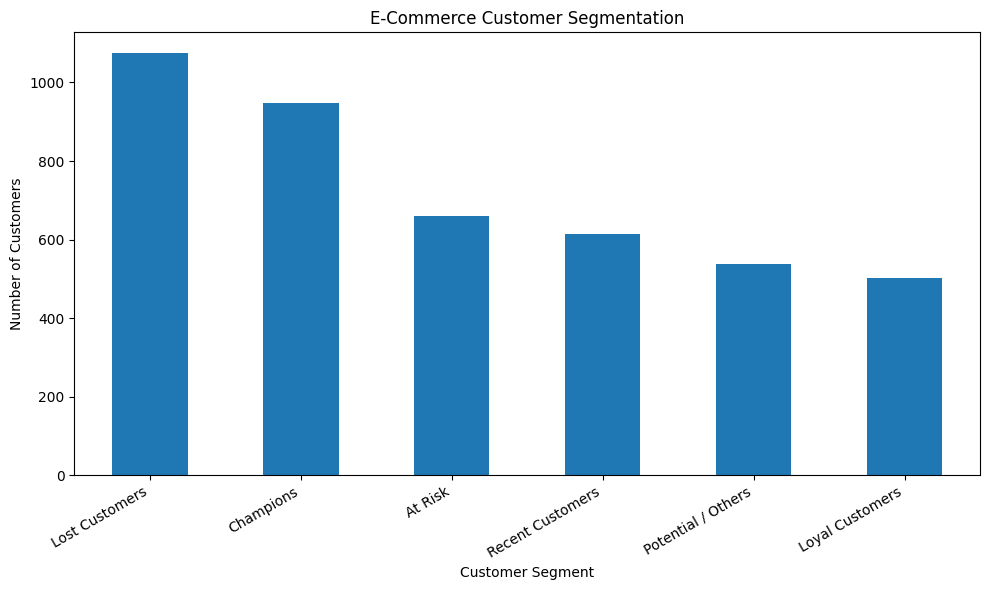

Segment-wise business summary:


,Segment,Customer_Count,Average_Recency,Average_Frequency,Total_Monetary,Customer_Percentage
2,Lost Customers,1074,216.68,1.10,524889.70,24.76
1,Champions,947,12.54,11.15,5755513.22,21.83
0,At Risk,661,150.64,3.41,826438.37,15.24
5,Recent Customers,614,16.95,1.79,549185.87,14.15
4,Potential / Others,539,52.05,1.57,329040.42,12.43
3,Loyal Customers,503,37.38,5.15,926340.32,11.60


In [5]:

import matplotlib.pyplot as plt

# Count customers in each segment
segment_counts = rfm["Segment"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")

plt.title("E-Commerce Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Calculate segment-level business metrics
segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Monetary=("Monetary", "sum")
).round(2).reset_index()

segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"] / len(rfm) * 100
).round(2)

print("Segment-wise business summary:")
display(segment_summary.sort_values("Customer_Count", ascending=False))


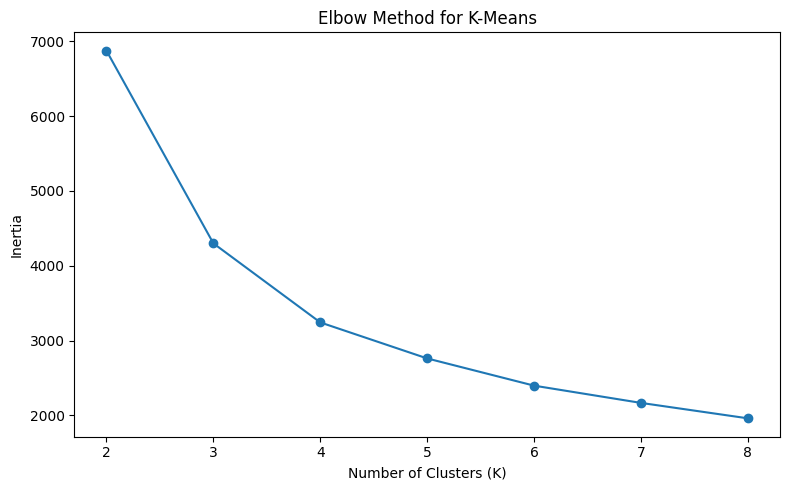

K-Means clustering completed!
Number of clusters: 4
Silhouette score: 0.38


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,0
1,12347,2,7,4310.00,3
2,12348,75,4,1797.24,0
3,12349,19,1,1757.55,0
4,12350,310,1,334.40,2
5,12352,36,8,2506.04,3
6,12353,204,1,89.00,2
7,12354,232,1,1079.40,2
8,12355,214,1,459.40,2
9,12356,23,3,2811.43,0


In [6]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Select RFM features
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce the effect of highly skewed values
X_log = X.copy()
X_log["Frequency"] = X_log["Frequency"].apply(lambda x: __import__("numpy").log1p(x))
X_log["Monetary"] = X_log["Monetary"].apply(lambda x: __import__("numpy").log1p(x))

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# Elbow method to help choose cluster count
inertias = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Fit the initial 4-cluster model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

# Evaluate cluster separation
score = silhouette_score(X_scaled, rfm["Cluster"])
print("K-Means clustering completed!")
print("Number of clusters:", rfm["Cluster"].nunique())
print("Silhouette score:", round(score, 3))

display(rfm[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster"]].head(10))


K-Means Cluster Summary:


,Cluster,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
0,0,1447,45.42,4.27,1667.67,2413117.99,33.36
1,1,1392,58.14,1.52,392.89,546901.18,32.09
2,2,941,259.18,1.38,390.20,367180.86,21.69
3,3,558,19.50,16.03,10007.54,5584207.87,12.86


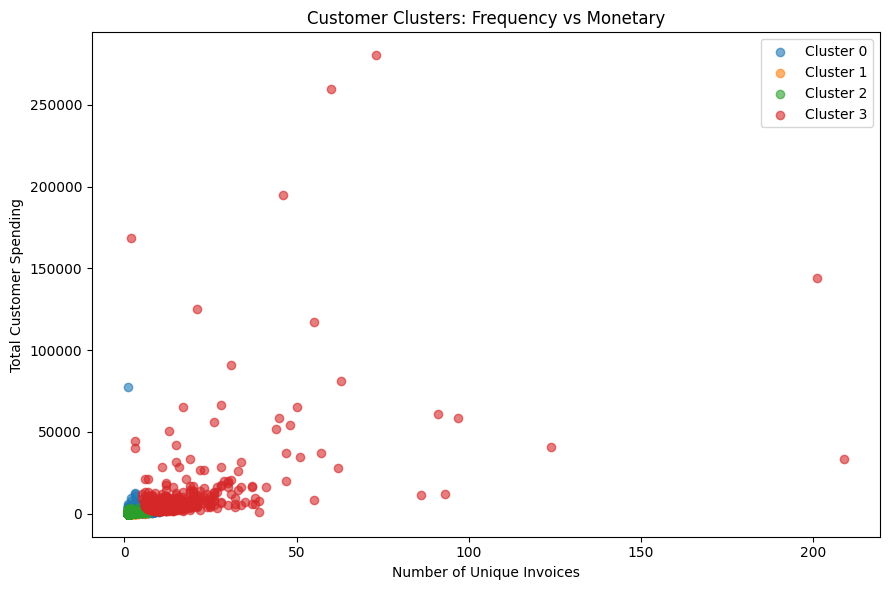

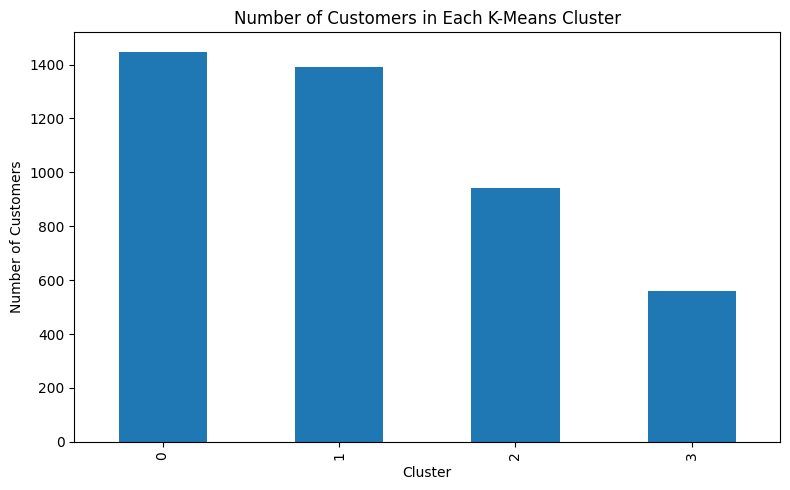

In [7]:

import matplotlib.pyplot as plt

# Summarize each K-Means cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2).reset_index()

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(rfm) * 100
).round(2)

print("K-Means Cluster Summary:")
display(cluster_summary)

# Visualize average spending and purchase frequency
plt.figure(figsize=(9, 6))

for cluster_id in sorted(rfm["Cluster"].unique()):
    cluster_data = rfm[rfm["Cluster"] == cluster_id]
    plt.scatter(
        cluster_data["Frequency"],
        cluster_data["Monetary"],
        label=f"Cluster {cluster_id}",
        alpha=0.6
    )

plt.title("Customer Clusters: Frequency vs Monetary")
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Total Customer Spending")
plt.legend()
plt.tight_layout()
plt.show()

# Visualize cluster sizes
plt.figure(figsize=(8, 5))
cluster_summary.set_index("Cluster")["Customer_Count"].plot(kind="bar")
plt.title("Number of Customers in Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [8]:

# Summarize customer segments from RFM analysis
insights = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Spending=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2).reset_index()

insights["Customer_Share_Percent"] = (
    insights["Customers"] / len(rfm) * 100
).round(2)

insights["Revenue_Share_Percent"] = (
    insights["Total_Revenue"] / rfm["Monetary"].sum() * 100
).round(2)

print("CUSTOMER SEGMENT BUSINESS INSIGHTS")
display(insights.sort_values("Total_Revenue", ascending=False))

# Identify largest customer group and highest-revenue group
largest_segment = insights.loc[insights["Customers"].idxmax()]
highest_revenue_segment = insights.loc[insights["Total_Revenue"].idxmax()]

print("\nKey Findings:")
print(
    f"Largest segment: {largest_segment['Segment']} "
    f"({int(largest_segment['Customers'])} customers)"
)
print(
    f"Highest-revenue segment: {highest_revenue_segment['Segment']} "
    f"(total revenue: {highest_revenue_segment['Total_Revenue']:,.2f})"
)

print("\nMARKETING RECOMMENDATIONS")

recommendations = {
    "Champions": "Reward with VIP benefits, early access and referral offers.",
    "Loyal Customers": "Use loyalty points, bundles and personalized offers.",
    "At Risk": "Send targeted win-back campaigns and relevant discounts.",
    "Lost Customers": "Test reactivation emails and limited-time comeback offers.",
    "Recent Customers": "Encourage a second purchase with onboarding offers.",
    "Potential / Others": "Test product recommendations and incentives."
}

for segment in insights["Segment"]:
    print(f"{segment}: {recommendations.get(segment, 'Review customer behaviour and test a targeted campaign.')}")


CUSTOMER SEGMENT BUSINESS INSIGHTS


,Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Spending,Total_Revenue,Customer_Share_Percent,Revenue_Share_Percent
1,Champions,947,12.54,11.15,6077.63,5755513.22,21.83,64.59
3,Loyal Customers,503,37.38,5.15,1841.63,926340.32,11.60,10.39
0,At Risk,661,150.64,3.41,1250.28,826438.37,15.24,9.27
5,Recent Customers,614,16.95,1.79,894.44,549185.87,14.15,6.16
2,Lost Customers,1074,216.68,1.10,488.72,524889.70,24.76,5.89
4,Potential / Others,539,52.05,1.57,610.46,329040.42,12.43,3.69



Key Findings:
Largest segment: Lost Customers (1074 customers)
Highest-revenue segment: Champions (total revenue: 5,755,513.22)

MARKETING RECOMMENDATIONS
At Risk: Send targeted win-back campaigns and relevant discounts.
Champions: Reward with VIP benefits, early access and referral offers.
Lost Customers: Test reactivation emails and limited-time comeback offers.
Loyal Customers: Use loyalty points, bundles and personalized offers.
Potential / Others: Test product recommendations and incentives.
Recent Customers: Encourage a second purchase with onboarding offers.


In [9]:

# Export customer-level RFM analysis and summary tables

output_file = "Ecommerce_Customer_Segmentation.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    rfm.to_excel(writer, sheet_name="RFM_Customer_Scores", index=False)
    segment_summary.to_excel(writer, sheet_name="Rule_Based_Summary", index=False)
    cluster_summary.to_excel(writer, sheet_name="KMeans_Summary", index=False)
    insights.to_excel(writer, sheet_name="Business_Insights", index=False)

print("Excel export completed:", output_file)

# Download the Excel file to your computer
from google.colab import files
files.download(output_file)


Excel export completed: Ecommerce_Customer_Segmentation.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>